# *Filoviridae* fold trees (GP, NP)

Proof of concept that ESM3Di 3Di groups the most similar structures together, here for the
*Filoviridae* glycoprotein (GP) and nucleoprotein (NP). Trees are built with `esm3di foldtree`
(ESM3Di and ProstT5) from NCBI protein sets (`INPUT_DIR`, outside the repository), keeping one
sequence per identical amino-acid sequence.

Tips are labelled `Genus-species_accession` from the NCBI lineages in
`../../ebola_data/ebola_data/Ebola_*_taxonomic_info.csv`. Accessions whose lineage ends above species
level are labelled `Genus-unassigned`, accessions without a lineage `Unknown-unassigned`. The
monophyly score is the share of internal nodes whose descendant tips all belong to one species; it
is a label-purity summary, not a measure of phylogenetic accuracy.

Steps: 0. deduplicate, 1. build the trees, 2. label, 3. score, 4. species clades, 5. jackknife,
6. without X-rich sequences, 7. one representative per species (genus level), 8. figures.

**Figures** (written to `figures/`): the GP trees of step 7 and of all sequences (panel a of Figure 2) and the GP trees
without X-rich sequences (a supplementary figure), which `paper/` assembles; and, not in the paper, all GP and NP trees
with and without X-rich sequences and the other trees of step 7. The genus relationships, drawn as support numbers on the species trees of Figure 2a,
are in `results/`. Scores: `results/filoviridae_monophyly.csv`.

In [1]:
import itertools
import os
import random
import statistics
import subprocess
import tempfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import toytree
from Bio import Phylo, SeqIO

import sys
sys.path.insert(0, "../shared")  # code shared by the phylogeny analyses
from foldtree_resample import build_tree, jackknife, load_allvall
from esm3di.workflow.scripts.run_madroot import run_mad_root
from monophyly import _splits, clade_recovery, filoviridae_labels, relabel_tree, score_monophyly, ultrametricity
from tree_plot import FIGURE2_PANEL_HEIGHT_MM, FIGURE2_SCORE_TABLE_TOP_MM, SUBTITLE_MM, genus_legend, parse_tip, score_table, species_colors, species_legend, species_tree_grid, tip_keys, tree_grid

EBOLA_DIR = Path("/work/FAC/FBM/DBC/cdessim2/default/dkim5/projects/viral/ebola")
INPUT_DIR = EBOLA_DIR / "data"             # {protein}_nodup.fasta
TAXONOMY_DIR = Path("../../ebola_data/ebola_data")
OUTPUT_DIR = Path("/scratch/fweikert/phylogeny/filoviridae_deduplicated")    # esm3di foldtree runs (not tracked)
DEDUP_DIR = OUTPUT_DIR / "inputs"          # {protein}_dedup.fasta + {protein}_dedup_groups.tsv
FIGURE_DIR = Path("figures")
CORES = min(32, os.cpu_count())

PROTEINS = {"gp": "GP", "np": "NP"}
MODELS = ("esm3di", "prostt5")
MAX_X = 0.05   # largest accepted share of unknown residues (X) per sequence (step 6)


def input_fasta(protein):
    return DEDUP_DIR / f"{protein}_dedup.fasta"


def raw_tree(model, protein):
    """Rooted tree written by esm3di foldtree."""
    return OUTPUT_DIR / f"{model}_{protein}" / f"{model}_struct_tree.PP.nwk.rooted"


def labelled_tree(model, protein):
    return OUTPUT_DIR / "labelled" / f"{model}_{protein}.nwk"

## 0. Deduplicate the input

Many accessions share the same amino-acid sequence. Identical sequences have distance 0 and
QuickTree joins them in an arbitrary order, which pads the tree with zero-length nodes. Keeps the
first accession of each identical sequence; `{protein}_dedup_groups.tsv` lists the accessions each
representative stands for. Existing files are kept.

In [2]:
DEDUP_DIR.mkdir(parents=True, exist_ok=True)
for protein in PROTEINS:
    if input_fasta(protein).exists():
        print(f"Exists, skipping: {input_fasta(protein)}")
        continue
    groups = {}   # sequence -> accessions, representative first
    records = {}  # sequence -> representative record
    for record in SeqIO.parse(INPUT_DIR / f"{protein}_nodup.fasta", "fasta"):
        seq = str(record.seq)
        groups.setdefault(seq, []).append(record.id)
        records.setdefault(seq, record)
    with open(input_fasta(protein), "w") as out:  # unwrapped, one line per sequence
        for record in records.values():
            out.write(f">{record.description}\n{record.seq}\n")
    pd.DataFrame([(accs[0], acc) for accs in groups.values() for acc in accs],
                 columns=["representative", "accession"]
                 ).to_csv(DEDUP_DIR / f"{protein}_dedup_groups.tsv", sep="\t", index=False)
    sizes = sorted((len(accs) for accs in groups.values()), reverse=True)
    print(f"{protein}: {sum(sizes)} sequences -> {len(sizes)} unique, largest groups {sizes[:5]}")

for protein in PROTEINS:
    lengths = [len(record.seq) for record in SeqIO.parse(input_fasta(protein), "fasta")]
    print(f"{protein}: {len(lengths)} sequences, lengths {min(lengths)}-{max(lengths)}, "
          f"mean {sum(lengths) / len(lengths):.1f}")

Exists, skipping: /scratch/fweikert/phylogeny/filoviridae_deduplicated/inputs/gp_dedup.fasta
Exists, skipping: /scratch/fweikert/phylogeny/filoviridae_deduplicated/inputs/np_dedup.fasta
gp: 550 sequences, lengths 596-688, mean 673.7
np: 499 sequences, lengths 588-749, mean 731.1


## 1. Build the trees

Runs `esm3di foldtree` once per protein and model; existing runs are skipped. Run on a GPU node
with ESM3Di installed.

In [3]:
for protein in PROTEINS:
    for model in MODELS:
        if raw_tree(model, protein).exists():
            print(f"Exists, skipping: {raw_tree(model, protein)}")
            continue
        cmd = ["esm3di", "foldtree", "-i", str(input_fasta(protein)),
               "-o", str(OUTPUT_DIR), "-d", f"{model}_{protein}", "-c", str(CORES)]
        if model == "prostt5":
            cmd.append("--use-prostt5")
        print(" ".join(cmd))
        subprocess.run(cmd, check=True)

Exists, skipping: /scratch/fweikert/phylogeny/filoviridae_deduplicated/esm3di_gp/esm3di_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/filoviridae_deduplicated/prostt5_gp/prostt5_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/filoviridae_deduplicated/esm3di_np/esm3di_struct_tree.PP.nwk.rooted
Exists, skipping: /scratch/fweikert/phylogeny/filoviridae_deduplicated/prostt5_np/prostt5_struct_tree.PP.nwk.rooted


## 2. Species labels

For accessions whose NCBI lookup failed when the taxonomy table was built (`IncompleteRead` in the
`error` column), the species is taken from the organism in the FASTA header, e.g. `[Ebola virus]`,
when all other accessions of that organism share one species.

A representative stands for several accessions with the identical sequence. If
the representative itself has no species in the taxonomy table, it takes the species of the other
accessions in its group (when they agree), so no species is lost by the choice of representative.


In [4]:
def species_labels(protein):
    """``Genus-species_accession`` per accession, see the note above for representatives."""
    labels = filoviridae_labels(TAXONOMY_DIR / f"Ebola_{PROTEINS[protein]}_taxonomic_info.csv",
                                INPUT_DIR / f"{protein}_nodup.fasta")
    groups = pd.read_csv(DEDUP_DIR / f"{protein}_dedup_groups.tsv", sep="\t")
    for representative, accessions in groups.groupby("representative")["accession"]:
        if "-unassigned_" not in labels.get(representative, "-unassigned_"):
            continue
        species = {labels[a].split("_")[0] for a in accessions
                   if a in labels and "-unassigned_" not in labels[a]}
        if len(species) == 1:
            labels[representative] = f"{species.pop()}_{representative}"
    return labels


for protein, name in PROTEINS.items():
    labels = species_labels(protein)
    for model in MODELS:
        relabel_tree(raw_tree(model, protein), labelled_tree(model, protein), labels, missing="unknown")
    tips = [leaf.name for leaf in Phylo.read(labelled_tree("esm3di", protein), "newick").get_terminals()]
    unassigned = [tip for tip in tips if "-unassigned_" in tip]
    print(f"{name}: {len(unassigned)} of {len(tips)} tips without a species {unassigned}")

GP: 0 of 550 tips without a species []


NP: 0 of 499 tips without a species []


## 3. Monophyly scores

In [5]:
METHOD_NAMES = {"esm3di": "ESM3Di FoldTree", "prostt5": "ProstT5 FoldTree"}
scores = pd.DataFrame([(name, METHOD_NAMES[model], *score_monophyly(labelled_tree(model, protein), verbose=False))
                       for protein, name in PROTEINS.items() for model in MODELS],
                      columns=["protein", "tree", "monophyletic", "internal_nodes", "fraction"])
scores.round(4)

,protein,tree,monophyletic,internal_nodes,fraction
0,GP,ESM3Di FoldTree,535,549,0.9745
1,GP,ProstT5 FoldTree,534,549,0.9727
2,NP,ESM3Di FoldTree,483,498,0.9699
3,NP,ProstT5 FoldTree,476,498,0.9558


## 4. Species clades

Which species (with at least two tips) form a clade, ignoring the root. For species that do not,
`foreign` lists the tips of other species in the smallest clade that holds the whole species.

In [6]:
rows = []
for protein, name in PROTEINS.items():
    for model in MODELS:
        for row in clade_recovery(labelled_tree(model, protein)):
            foreign = Counter(tip.split("_")[0] for tip in row["foreign"])
            rows.append((name, METHOD_NAMES[model], row["group"], row["tips"], row["clade"],
                         ", ".join(f"{group} ({n})" for group, n in foreign.most_common())))
species_clades = pd.DataFrame(rows, columns=["protein", "tree", "species", "tips", "clade", "foreign"])
print(species_clades.groupby(["protein", "tree"])["clade"].agg(clades="sum", species="size").to_string())
species_clades[~species_clades["clade"]]

                          clades  species
protein tree                             
GP      ESM3Di FoldTree        6        7
        ProstT5 FoldTree       5        7
NP      ESM3Di FoldTree        6        7
        ProstT5 FoldTree       6        7


,protein,tree,species,tips,clade,foreign
5,GP,ESM3Di FoldTree,Orthoebolavirus-zairense,417,False,"Orthoebolavirus-sudanense (31), Orthoebolaviru..."
12,GP,ProstT5 FoldTree,Orthoebolavirus-zairense,417,False,"Orthoebolavirus-sudanense (31), Orthoebolaviru..."
13,GP,ProstT5 FoldTree,Orthomarburgvirus-marburgense,71,False,"Dianlovirus-dehongense (1), Dianlovirus-mengla..."
19,NP,ESM3Di FoldTree,Orthoebolavirus-zairense,404,False,"Orthoebolavirus-sudanense (25), Orthoebolaviru..."
26,NP,ProstT5 FoldTree,Orthoebolavirus-zairense,404,False,"Orthoebolavirus-sudanense (25), Orthoebolaviru..."


## 5. Jackknife

Paired delete-20% jackknife as in `flaviviridae_jackknife.ipynb`: each replicate drops the same
random 20% of the sequences for both methods and rebuilds the trees from the all-vs-all results.
Reports the paired difference ESM3Di − ProstT5 in the monophyly fraction, and in how many
replicates each species forms a clade. Results are cached in `JACKKNIFE_CSV`; about one CPU-hour
for 20 replicates, set `WORKERS` to the available cores.

In [7]:
QUICKTREE = next(OUTPUT_DIR.glob(".snakemake_conda/*/bin/quicktree"))   # installed by esm3di foldtree
JACKKNIFE_CSV = Path("results/filoviridae_jackknife_dedup.csv")
REPLICATES = 20
FRACTION = 0.8
WORKERS = min(8, os.cpu_count())

allvall = {(p, m): load_allvall(OUTPUT_DIR / f"{m}_{p}" / "allvall_1.csv") for p in PROTEINS for m in MODELS}
if JACKKNIFE_CSV.exists():
    replicates = pd.read_csv(JACKKNIFE_CSV, keep_default_na=False)
    print(f"Loaded {len(replicates)} rows from {JACKKNIFE_CSV}")
else:
    tables = []
    for protein, name in PROTEINS.items():
        labels = species_labels(protein)
        ids = set(allvall[protein, "esm3di"]["query"])
        labels.update({acc: f"Unknown-unassigned_{acc}" for acc in ids - labels.keys()})
        table = jackknife({METHOD_NAMES[m]: allvall[protein, m] for m in MODELS}, labels, QUICKTREE,
                          replicates=REPLICATES, fraction=FRACTION, seed=0, workers=WORKERS)
        tables.append(table.assign(protein=name))
    replicates = pd.concat(tables, ignore_index=True)
    JACKKNIFE_CSV.parent.mkdir(exist_ok=True)
    replicates.to_csv(JACKKNIFE_CSV, index=False)

paired = replicates.pivot_table(index=["protein", "replicate"], columns="method", values="fraction")
difference = paired["ESM3Di FoldTree"] - paired["ProstT5 FoldTree"]
display(pd.DataFrame({
    "mean difference": difference.groupby("protein").mean(),
    "2.5%": difference.groupby("protein").quantile(0.025),
    "97.5%": difference.groupby("protein").quantile(0.975),
    "ESM3Di higher": (difference > 0).groupby("protein").mean(),
    "ProstT5 higher": (difference < 0).groupby("protein").mean(),
}).round(4))

# Share of replicates in which a species does not form a clade
not_clade = (replicates.assign(species=replicates["not_clades"].str.split(";")).explode("species")
             .query("species != ''").groupby(["protein", "method", "species"]).size()
             .unstack("method", fill_value=0) / REPLICATES)
not_clade

Loaded 80 rows from results/filoviridae_jackknife_dedup.csv


,mean difference,2.5%,97.5%,ESM3Di higher,ProstT5 higher
protein,,,,,
GP,0.0046,-0.1035,0.0843,0.65,0.2
NP,0.0317,-0.0682,0.1033,0.70,0.3


method                                  ESM3Di FoldTree  ProstT5 FoldTree
protein species                                                          
GP      Orthoebolavirus-bundibugyoense             0.05              0.00
        Orthoebolavirus-zairense                   0.85              0.75
        Orthomarburgvirus-marburgense              0.00              0.65
NP      Orthoebolavirus-zairense                   1.00              1.00

## 6. Without sequences rich in unknown residues

Many sequences are partial, with stretches of unknown residues (`X`); 3Di predicted there is noise,
and such sequences split *O. zairense* in both trees. Here sequences with more than `MAX_X` of their
residues unknown are left out, and the trees are rebuilt from the all-vs-all results of step 1
(existing trees are reused). The table compares them with the deduplicated trees: monophyly score,
species with at least two tips that form a clade, and genera with at least two tips that do not
(with the tips of other genera in the smallest clade that holds the genus; rooting ignored).

In [8]:
FILTERED_DIR = OUTPUT_DIR / f"filtered_x{round(MAX_X * 100)}"


def filtered_tree(model, protein):
    return FILTERED_DIR / f"{model}_{protein}.nwk"


def genus_clades(tree_file):
    """clade_recovery with the tips labelled by genus."""
    names = [leaf.name for leaf in Phylo.read(tree_file, "newick").get_terminals()]
    with tempfile.TemporaryDirectory() as workdir:
        by_genus = {n: f"{n.split('-')[0]}_{n.split('_', 1)[1]}" for n in names}
        return clade_recovery(relabel_tree(tree_file, Path(workdir) / "genus.nwk", by_genus))


FILTERED_DIR.mkdir(parents=True, exist_ok=True)
rows = []
for protein, name in PROTEINS.items():
    labels = species_labels(protein)
    records = list(SeqIO.parse(input_fasta(protein), "fasta"))
    keep = {r.id for r in records if str(r.seq).count("X") / len(r.seq) <= MAX_X}
    species_all = {labels.get(r.id, "Unknown-unassigned_").split("_")[0] for r in records}
    species_kept = {labels.get(r, "Unknown-unassigned_").split("_")[0] for r in keep}
    print(f"{name}: {len(keep)} of {len(records)} sequences with at most {MAX_X:.0%} X; "
          f"species lost: {sorted(species_all - species_kept) or 'none'}")
    for model in MODELS:
        if not filtered_tree(model, protein).exists():
            subset = allvall[protein, model]
            subset = subset[subset["query"].isin(keep) & subset["target"].isin(keep)]
            with tempfile.TemporaryDirectory() as workdir:
                relabel_tree(build_tree(subset, workdir, QUICKTREE), filtered_tree(model, protein), labels,
                             missing="unknown")
        for data, tree in (("deduplicated", labelled_tree(model, protein)),
                           (f"X <= {MAX_X:.0%}", filtered_tree(model, protein))):
            mono, internal, fraction = score_monophyly(tree, verbose=False)
            species = clade_recovery(tree)
            genera = [g for g in genus_clades(tree) if not g["clade"]]
            rows.append({
                "protein": name, "data": data, "tree": METHOD_NAMES[model], "tips": internal + 1,
                "monophyletic": f"{mono}/{internal} ({fraction:.4f})",
                "species clades": f"{sum(s['clade'] for s in species)}/{len(species)}",
                "genera not clades": "; ".join(
                    f"{g['group']} (+{', '.join(sorted({t.split('_')[0] for t in g['foreign']}))})"
                    for g in genera) or "-",
            })
filtered = pd.DataFrame(rows).set_index(["protein", "data", "tree"]).sort_index()
filtered.to_csv("results/filoviridae_monophyly.csv")
filtered

GP: 417 of 550 sequences with at most 5% X; species lost: none


NP: 373 of 499 sequences with at most 5% X; species lost: none


tips      monophyletic species clades  \
protein data         tree                                                      
GP      X <= 5%      ESM3Di FoldTree    417  403/416 (0.9688)            7/7   
                     ProstT5 FoldTree   417  403/416 (0.9688)            7/7   
        deduplicated ESM3Di FoldTree    550  535/549 (0.9745)            6/7   
                     ProstT5 FoldTree   550  534/549 (0.9727)            5/7   
NP      X <= 5%      ESM3Di FoldTree    373  363/372 (0.9758)            7/7   
                     ProstT5 FoldTree   373  363/372 (0.9758)            7/7   
        deduplicated ESM3Di FoldTree    499  483/498 (0.9699)            6/7   
                     ProstT5 FoldTree   499  476/498 (0.9558)            6/7   

                                                                       genera not clades  
protein data         tree                                                                 
GP      X <= 5%      ESM3Di FoldTree   Dianlovirus (+Orthomarburgvirus); Thamnovirus ...  
                     ProstT5 FoldTree  Dianlovirus (+Loebevirus, Oblavirus, Orthomarb...  
        deduplicated ESM3Di FoldTree   Dianlovirus (+Orthomarburgvirus); Thamnovirus ...  
                     ProstT5 FoldTree  Dianlovirus (+Loebevirus, Oblavirus, Orthomarb...  
NP      X <= 5%      ESM3Di FoldTree                                                   -  
                     ProstT5 FoldTree                                                  -  
        deduplicated ESM3Di FoldTree                       Orthoebolavirus (+Cuevavirus)  
                     ProstT5 FoldTree                      Orthoebolavirus (+Cuevavirus)

## 7. One representative per species

Within a species the sequences are nearly identical, and species of one genus share about 50-75%
amino-acid identity, so species-level grouping is easy for any method. Between genera the identity
drops to about 20-25%, the range where structure is expected to help. Here each species is
represented by one sequence (at most `MAX_X` unknown residues `X`; among those, X-free sequences first, then the length
closest to the species median), and the 3Di trees are
compared with an amino-acid tree (MAFFT, IQ-TREE with ModelFinder and 1000 ultrafast bootstraps) on
genus relationships that are established in the literature. A relationship counts as recovered if
its genera form one side of a bipartition (rooting ignored); a relationship is tested with the genera
present in a protein's data (at least two, or its single genus).

The 3Di trees are rebuilt from the all-vs-all results of step 1 with the steps of
`esm3di foldtree` (`foldtree_resample.build_tree`): a pair's identity does not depend on the other
sequences in the search, so this equals rerunning the workflow on the representatives.


In [9]:
GENUS_DIR = OUTPUT_DIR / "genus_level"
AA_TOOLS = "module load gcc/11.5.0 mafft/7.525 iq-tree/2.4.0"           # MAFFT and IQ-TREE (cluster modules)
DRAWS = 50   # random choices of representatives for the 3Di trees

GENUS_TESTS = {
    "Orthoebolavirus": ("Orthoebolavirus",),
    "Orthoebolavirus + Cuevavirus": ("Orthoebolavirus", "Cuevavirus"),
    "Orthomarburgvirus + Dianlovirus": ("Orthomarburgvirus", "Dianlovirus"),
    "Mammalian filoviruses": ("Orthoebolavirus", "Cuevavirus", "Orthomarburgvirus", "Dianlovirus"),
    "Thamnovirus": ("Thamnovirus",),
}

# A test whose genera are one side of a split that is worth naming on both sides: the remaining
# genera of each protein's data are the fish-infecting filoviruses (GP: Thamnovirus, Oblavirus,
# Loebevirus; NP: Striavirus, Tapjovirus), so this one row is the mammalian/fish bipartition.
GENUS_TEST_LABELS = {"Mammalian filoviruses": "Mammalian clade vs fish-infecting clade"}


def genus(tip):
    return tip.split("-")[0]


def candidates(protein, labels):
    """Accessions per species: labelled to species level and with at most MAX_X unknown residues."""
    by_species = {}
    for record in SeqIO.parse(input_fasta(protein), "fasta"):
        species = labels.get(record.id, "Unknown-unassigned_").split("_")[0]
        if str(record.seq).count("X") / len(record.seq) <= MAX_X and "unassigned" not in species:
            by_species.setdefault(species, []).append(record)
    return by_species


def median_length_representatives(by_species):
    reps = {}
    for species, records in by_species.items():
        median = statistics.median(len(r.seq) for r in records)
        reps[species] = min(records, key=lambda r: ("X" in r.seq, abs(len(r.seq) - median)))
    return reps


def genus_tests(tree_file):
    """Recovered (True/False) per genus test that applies: its genus, or at least two of its genera,
    must be in the tree; the test then uses the genera present."""
    tips, splits = _splits(Phylo.read(tree_file, "newick"))
    present = {genus(tip) for tip in tips}
    result = {}
    for test, genera in GENUS_TESTS.items():
        group = frozenset(tip for tip in tips if genus(tip) in genera)
        if len(present & set(genera)) >= min(2, len(genera)) and 2 <= len(group) <= len(tips) - 2:
            result[test] = group in splits or tips - group in splits
    return result


def tree_3di(allvall, names, output):
    """Rebuilt esm3di foldtree tree of the accessions in ``names`` (accession -> tip label)."""
    subset = allvall[allvall["query"].isin(names) & allvall["target"].isin(names)]
    with tempfile.TemporaryDirectory() as workdir:
        return relabel_tree(build_tree(subset, workdir, QUICKTREE), output, names)


def aa_tree(fasta, prefix):
    """MAFFT + IQ-TREE tree; reused unless the FASTA changed since."""
    treefile = Path(f"{prefix}.treefile")
    if not treefile.exists() or treefile.stat().st_mtime < Path(fasta).stat().st_mtime:
        subprocess.run(["bash", "-lc", f"{AA_TOOLS} && mafft --auto --quiet {fasta} > {prefix}.msa && "
                        f"iqtree2 -s {prefix}.msa -m MFP -B 1000 -T 1 --seed 1 --prefix {prefix} -redo --quiet"],
                       check=True, stdout=subprocess.DEVNULL)
    return treefile


def support(tree_file, group):
    """Bootstrap support of the branch that splits off ``group``."""
    tree = Phylo.read(tree_file, "newick")
    tips = {leaf.name for leaf in tree.get_terminals()}
    for clade in tree.get_nonterminals():
        side = {leaf.name for leaf in clade.get_terminals()}
        if group in (side, tips - side):
            return clade.confidence


GENUS_DIR.mkdir(parents=True, exist_ok=True)
allvall = {(p, m): load_allvall(OUTPUT_DIR / f"{m}_{p}" / "allvall_1.csv") for p in PROTEINS for m in MODELS}
genus_trees, rows = {}, []
for protein, name in PROTEINS.items():
    labels = species_labels(protein)
    reps = median_length_representatives(candidates(protein, labels))
    fasta = GENUS_DIR / f"{protein}_representatives.fasta"
    text = "".join(f">{species}_{record.id}\n{record.seq}\n" for species, record in sorted(reps.items()))
    if not fasta.exists() or fasta.read_text() != text:   # keeps the amino-acid tree cache valid
        fasta.write_text(text)
    names = {record.id: f"{species}_{record.id}" for species, record in reps.items()}
    trees = {METHOD_NAMES[m]: tree_3di(allvall[protein, m], names, GENUS_DIR / f"{protein}_{m}.nwk") for m in MODELS}
    trees["Amino acid (IQ-TREE)"] = aa_tree(fasta, GENUS_DIR / f"{protein}_aa")
    genus_trees[protein] = trees
    aa_tips, aa_splits = _splits(Phylo.read(trees["Amino acid (IQ-TREE)"], "newick"))
    for tree_name, tree_file in trees.items():
        tips, splits = _splits(Phylo.read(tree_file, "newick"))
        row = {"protein": name, "tree": tree_name, "species": len(tips),
               "RF to amino-acid tree": len(splits ^ aa_splits)}
        for test, recovered in genus_tests(tree_file).items():
            row[test] = "yes" if recovered else "no"
            if tree_name.startswith("Amino") and recovered:
                group = frozenset(t for t in tips if genus(t) in GENUS_TESTS[test])
                row[test] += f" ({support(tree_file, group):.0f})"
        rows.append(row)
genus_table = pd.DataFrame(rows).set_index(["protein", "tree"]).fillna("")
genus_table.to_csv("results/filoviridae_species_trees.csv")
genus_table

species  RF to amino-acid tree Orthoebolavirus  \
protein tree                                                                   
GP      ESM3Di FoldTree            14                      2             yes   
        ProstT5 FoldTree           14                      4             yes   
        Amino acid (IQ-TREE)       14                      0       yes (100)   
NP      ESM3Di FoldTree            10                      2             yes   
        ProstT5 FoldTree           10                      2             yes   
        Amino acid (IQ-TREE)       10                      0        yes (96)   

                             Orthomarburgvirus + Dianlovirus  \
protein tree                                                   
GP      ESM3Di FoldTree                                  yes   
        ProstT5 FoldTree                                  no   
        Amino acid (IQ-TREE)                        yes (53)   
NP      ESM3Di FoldTree                                        
        ProstT5 FoldTree                                       
        Amino acid (IQ-TREE)                                   

                             Mammalian filoviruses Thamnovirus  \
protein tree                                                     
GP      ESM3Di FoldTree                        yes         yes   
        ProstT5 FoldTree                       yes         yes   
        Amino acid (IQ-TREE)             yes (100)    yes (93)   
NP      ESM3Di FoldTree                        yes               
        ProstT5 FoldTree                       yes               
        Amino acid (IQ-TREE)             yes (100)               

                             Orthoebolavirus + Cuevavirus  
protein tree                                               
GP      ESM3Di FoldTree                                    
        ProstT5 FoldTree                                   
        Amino acid (IQ-TREE)                               
NP      ESM3Di FoldTree                               yes  
        ProstT5 FoldTree                              yes  
        Amino acid (IQ-TREE)                     yes (95)

### Identity between the representatives

Pairwise identity of the species representatives: amino-acid identity in the MAFFT alignment of the
amino-acid tree (identical positions / positions without a gap in either sequence) and the 3Di
identity (Foldseek `fident`, mean of both search directions) that the 3Di trees are built from.
Pairs are split into species of the same genus, Orthomarburgvirus–Dianlovirus (the relationship
on which the methods differ) and species of other genera. The figure is saved as
`figures/filoviridae_species_identity.svg`.

Amino acid (MAFFT)               \
                                                     min median   max   
protein pair                                                            
GP      Orthomarburgvirus–Dianlovirus               0.41   0.48  0.55   
        other genera                                0.09   0.13  0.36   
        same genus                                  0.43   0.60  0.74   
NP      other genera                                0.19   0.26  0.47   
        same genus                                  0.65   0.68  0.79   

                                      ESM3Di FoldTree               \
                                                  min median   max   
protein pair                                                         
GP      Orthomarburgvirus–Dianlovirus            0.35   0.41  0.46   
        other genera                             0.07   0.12  0.34   
        same genus                               0.34   0.53  0.73   
NP      other genera                             0.14   0.24  0.47   
        same genus                               0.65   0.67  0.77   

                                      ProstT5 FoldTree               
                                                   min median   max  
protein pair                                                         
GP      Orthomarburgvirus–Dianlovirus             0.33   0.41  0.50  
        other genera                              0.08   0.13  0.34  
        same genus                                0.34   0.56  0.73  
NP      other genera                              0.16   0.24  0.47  
        same genus                                0.64   0.66  0.78

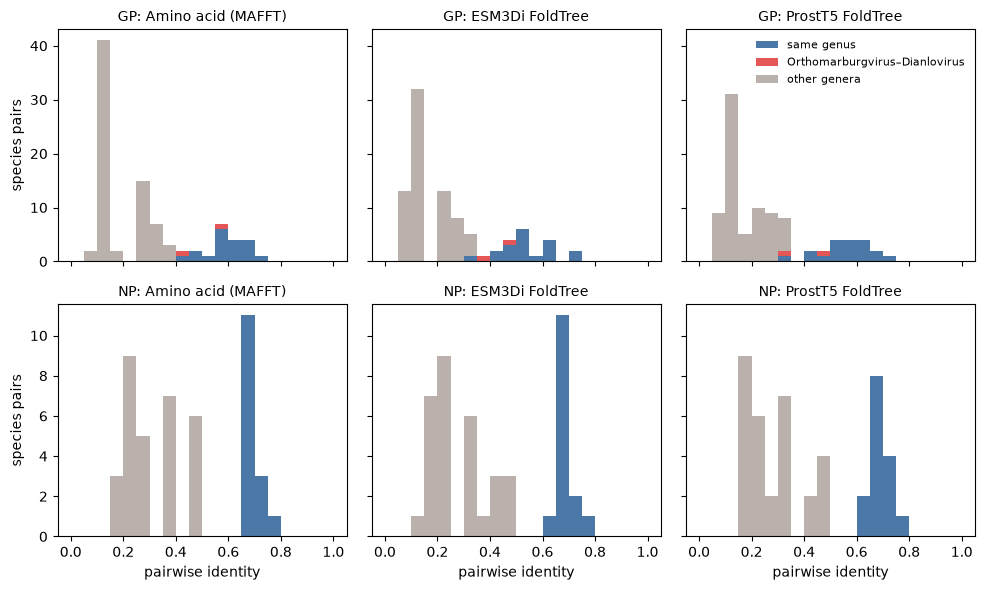

In [10]:
MEASURES = ("Amino acid (MAFFT)", *(METHOD_NAMES[m] for m in MODELS))
PAIR_CLASSES = ("same genus", "Orthomarburgvirus–Dianlovirus", "other genera")


def pair_class(a, b):
    genera = {genus(a), genus(b)}
    if len(genera) == 1:
        return PAIR_CLASSES[0]
    return PAIR_CLASSES[1] if genera == {"Orthomarburgvirus", "Dianlovirus"} else PAIR_CLASSES[2]


def alignment_identity(msa):
    """Pairwise identity in the MSA: identical positions / positions without a gap in either."""
    records = {r.id: str(r.seq).upper() for r in SeqIO.parse(msa, "fasta")}
    identity = {}
    for a, b in itertools.combinations(sorted(records), 2):
        aligned = [(x, y) for x, y in zip(records[a], records[b]) if x != "-" and y != "-"]
        identity[a, b] = sum(x == y for x, y in aligned) / len(aligned)
    return identity


def fident(allvall, tips):
    """3Di identity of each pair as the trees use it: mean of both search directions (0 if no hit)."""
    accession = {tip.split("_", 1)[1]: tip for tip in tips}
    hits = allvall[allvall["query"].isin(accession) & allvall["target"].isin(accession)]
    total = Counter()
    for query, target, value in zip(hits["query"], hits["target"], hits["fident"]):
        if query != target:
            total[tuple(sorted((accession[query], accession[target])))] += value / 2
    return total


rows = []
for protein, name in PROTEINS.items():
    aa = alignment_identity(GENUS_DIR / f"{protein}_aa.msa")
    tips = sorted({tip for pair in aa for tip in pair})
    three_di = {METHOD_NAMES[m]: fident(allvall[protein, m], tips) for m in MODELS}
    for a, b in aa:
        rows.append({"protein": name, "a": a, "b": b, "pair": pair_class(a, b),
                     MEASURES[0]: aa[a, b], **{method: values[a, b] for method, values in three_di.items()}})
identity = pd.DataFrame(rows)

fig, axes = plt.subplots(len(PROTEINS), len(MEASURES), figsize=(10, 3 * len(PROTEINS)), sharex=True, sharey="row")
colors = dict(zip(PAIR_CLASSES, ("#4C78A8", "#E45756", "#BAB0AC")))
bins = [i / 20 for i in range(21)]
for row_axes, (protein, name) in zip(axes, PROTEINS.items()):
    pairs = identity[identity["protein"] == name]
    for ax, measure in zip(row_axes, MEASURES):
        ax.hist([pairs.loc[pairs["pair"] == c, measure] for c in PAIR_CLASSES], bins=bins, stacked=True,
                color=[colors[c] for c in PAIR_CLASSES], label=PAIR_CLASSES)
        ax.set_title(f"{name}: {measure}", fontsize=10)
    row_axes[0].set_ylabel("species pairs")
for ax in axes[-1]:
    ax.set_xlabel("pairwise identity")
axes[0][-1].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("figures/filoviridae_species_identity.svg")

identity.groupby(["protein", "pair"])[list(MEASURES)].agg(["min", "median", "max"]).round(2)

### Robustness to the choice of representatives

The 3Di trees for `DRAWS` random choices of one representative per species (amino-acid trees are
not rebuilt). Share of draws in which each relationship is recovered.


In [11]:
rows = []
for protein, name in PROTEINS.items():
    labels = species_labels(protein)
    by_species = candidates(protein, labels)
    for draw in range(DRAWS):
        rng = random.Random(draw)
        names = {}
        for species, records in sorted(by_species.items()):
            record = rng.choice(records)
            names[record.id] = f"{species}_{record.id}"
        for model in MODELS:
            with tempfile.TemporaryDirectory() as workdir:
                tree = tree_3di(allvall[protein, model], names, Path(workdir) / "tree.nwk")
                tests, cv = genus_tests(tree), ultrametricity(tree)
            rows.append({"protein": name, "tree": METHOD_NAMES[model], "draw": draw, "root_to_tip_cv": cv, **tests})
draws = pd.DataFrame(rows)
draw_shares = draws.groupby(["protein", "tree"])[[t for t in GENUS_TESTS if t in draws]].mean()
draw_shares.to_csv("results/filoviridae_species_tree_draws.csv")
draw_shares

Orthoebolavirus Orthoebolavirus + Cuevavirus  \
protein tree                                                             
GP      ESM3Di FoldTree               1.0                          NaN   
        ProstT5 FoldTree              1.0                          NaN   
NP      ESM3Di FoldTree               1.0                          1.0   
        ProstT5 FoldTree              1.0                          1.0   

                         Orthomarburgvirus + Dianlovirus  \
protein tree                                               
GP      ESM3Di FoldTree                              1.0   
        ProstT5 FoldTree                             0.0   
NP      ESM3Di FoldTree                              NaN   
        ProstT5 FoldTree                             NaN   

                          Mammalian filoviruses Thamnovirus  
protein tree                                                 
GP      ESM3Di FoldTree                     1.0         1.0  
        ProstT5 FoldTree                    1.0        0.98  
NP      ESM3Di FoldTree                     1.0         NaN  
        ProstT5 FoldTree                    1.0         NaN

### Genus relationships: the support numbers of Figure 2a

One row per established genus relationship: how many of the `DRAWS` random choices of representatives give a tree that
recovers it, for each method. These shares are written at the matching nodes of the species trees of Figure 2a, as a
percentage; a relationship a tree does not recover has no node there and so no number. The relationship is named by the
genera of the test that the protein's data contains, as the figures name them. There is no amino-acid column: between
genera these sequences are around 17% identical (`pairwise_identity.ipynb`), too divergent for a sequence tree to serve
as a reference. Written to `results/filoviridae_genus_relationships.csv`.


In [12]:
METHODS = [METHOD_NAMES[model] for model in MODELS]

rows = []
for protein, name in PROTEINS.items():
    by_species = candidates(protein, species_labels(protein))
    present = {species.split("-")[0] for species in by_species}
    for test, genera in GENUS_TESTS.items():
        shares = draw_shares.loc[name, test] if test in draw_shares else None
        if shares is None or shares.isna().all():
            continue                        # the genera of this test are not in this protein's data
        tested = [genus_name for genus_name in genera if genus_name in present]
        size = sum(species.split("-")[0] in tested for species in by_species)
        label = GENUS_TEST_LABELS.get(test)  # a split named on both sides: give both sizes
        rows.append({"protein": name, "clade": label or " + ".join(tested),
                     "species": f"{size} vs {len(by_species) - size}" if label else str(size),
                     **{method: f"{shares[method] * DRAWS:.0f}/{DRAWS}" for method in METHODS}})
relationships = pd.DataFrame(rows)
relationships.to_csv("results/filoviridae_genus_relationships.csv", index=False)
relationships

,protein,clade,species,ESM3Di FoldTree,ProstT5 FoldTree
0,GP,Orthoebolavirus,6,50/50,50/50
1,GP,Orthomarburgvirus + Dianlovirus,3,50/50,0/50
2,GP,Mammalian clade vs fish-infecting clade,9 vs 5,50/50,50/50
3,GP,Thamnovirus,3,50/50,49/50
4,NP,Orthoebolavirus,6,50/50,50/50
5,NP,Orthoebolavirus + Cuevavirus,7,50/50,50/50
6,NP,Mammalian clade vs fish-infecting clade,8 vs 2,50/50,50/50


### Supplementary table: GP accessions

One row per accession of the GP data: its species, the accession that represents its identical sequence in the trees (one per
unique sequence), and whether that sequence is in the trees without X-rich sequences and is the species representative of
the trees of step 7. An accession without a species of its own takes that of its representative. Written to
`results/filoviridae_gp_accessions.csv`.


In [13]:
labels = species_labels("gp")


def species_name(accession):
    return labels.get(accession, "").split("_")[0]


def tree_accessions(tree_file):
    return {leaf.name.split("_", 1)[1] for leaf in Phylo.read(tree_file, "newick").get_terminals()}


accessions = pd.read_csv(DEDUP_DIR / "gp_dedup_groups.tsv", sep="\t").rename(columns={"representative": "unique_sequence_representative"})
own = accessions["accession"].map(species_name)
inherited = accessions["unique_sequence_representative"].map(species_name)
accessions.insert(1, "species", own.where(own != "", inherited).where(lambda s: ~s.str.contains("unassigned"), inherited).str.replace("-", " "))
filtered = tree_accessions(filtered_tree("esm3di", "gp"))
accessions["in_trees_x_at_most_5_percent"] = accessions["unique_sequence_representative"].isin(filtered)
species_reps = tree_accessions(genus_trees["gp"][METHOD_NAMES["esm3di"]])
accessions["species_representative"] = accessions["accession"].isin(species_reps)
accessions = accessions[["accession", "species", "unique_sequence_representative", "in_trees_x_at_most_5_percent", "species_representative"]]
accessions.to_csv("results/filoviridae_gp_accessions.csv", index=False)
assert accessions["unique_sequence_representative"].nunique() == 550 and accessions["species"].notna().all()
print(len(accessions), "accessions,", accessions["unique_sequence_representative"].nunique(), "unique sequences,",
      accessions["species"].nunique(), "species,", accessions["species"].str.contains("unassigned").sum(), "without a species,",
      accessions["species_representative"].sum(), "species representatives")
accessions.head()


2869 accessions, 550 unique sequences, 14 species, 0 without a species, 14 species representatives


,accession,species,unique_sequence_representative,in_trees_x_at_most_5_percent,species_representative
0,CAA78117.1,Orthomarburgvirus marburgense,CAA78117.1,True,True
1,ABA87127.1,Orthomarburgvirus marburgense,CAA78117.1,True,False
2,YP_001531156.1,Orthomarburgvirus marburgense,CAA78117.1,True,False
3,AAB81004.1,Orthoebolavirus zairense,AAB81004.1,True,True
4,AAC54887.1,Orthoebolavirus zairense,AAB81004.1,True,False


### Ultrametricity

Ultrametricity at the MAD root. It is shown with monophyly on the GP trees of all sequences (Figure 2a) and without
X-rich sequences (Supplementary Fig. 4), for completeness and as for *Flaviviridae*, but it is not stable here: removing
the X-rich sequences raises the ESM3Di value from 0.007 to 0.074 and reverses its comparison with ProstT5 (0.048 and 0.043).
It is therefore not used to compare the methods on *Filoviridae*. The species trees have only 10-14 tips and are drawn at
another root, so they show none. `results/filoviridae_ultrametricity.csv`.

In [14]:
def species_cv(tree_file):
    """Ultrametricity at the MAD root; the amino-acid trees (IQ-TREE) are unrooted and get MAD-rooted here."""
    if Path(tree_file).suffix != ".treefile":
        return ultrametricity(tree_file)
    with tempfile.TemporaryDirectory() as workdir:
        copy = Path(workdir) / "tree.nwk"
        copy.write_bytes(Path(tree_file).read_bytes())
        return ultrametricity(run_mad_root(copy))


rows = []
for protein, name in PROTEINS.items():
    for tree_name, tree_file in genus_trees[protein].items():
        rows.append({"protein": name, "trees": "one per species", "tree": tree_name, "root_to_tip_cv": species_cv(tree_file)})
    for model in MODELS:
        for data, tree_file in (("all sequences", labelled_tree(model, protein)), (f"X <= {MAX_X:.0%}", filtered_tree(model, protein))):
            rows.append({"protein": name, "trees": data, "tree": METHOD_NAMES[model], "root_to_tip_cv": ultrametricity(tree_file)})
cv_table = pd.DataFrame(rows).set_index(["protein", "trees", "tree"]).sort_index()
cv_draws = draws.groupby(["protein", "tree"])["root_to_tip_cv"].describe(percentiles=[0.025, 0.975])[["mean", "2.5%", "97.5%"]]
cv_table.to_csv("results/filoviridae_ultrametricity.csv")
display(cv_table.round(3), cv_draws.round(3))


root_to_tip_cv
protein trees           tree                                
GP      X <= 5%         ESM3Di FoldTree                0.074
                        ProstT5 FoldTree               0.043
        all sequences   ESM3Di FoldTree                0.007
                        ProstT5 FoldTree               0.048
        one per species Amino acid (IQ-TREE)           0.012
                        ESM3Di FoldTree                0.008
                        ProstT5 FoldTree               0.017
NP      X <= 5%         ESM3Di FoldTree                0.011
                        ProstT5 FoldTree               0.011
        all sequences   ESM3Di FoldTree                0.045
                        ProstT5 FoldTree               0.019
        one per species Amino acid (IQ-TREE)           0.002
                        ESM3Di FoldTree                0.004
                        ProstT5 FoldTree               0.003

mean   2.5%  97.5%
protein tree                                 
GP      ESM3Di FoldTree   0.005  0.003  0.008
        ProstT5 FoldTree  0.019  0.014  0.024
NP      ESM3Di FoldTree   0.003  0.001  0.005
        ProstT5 FoldTree  0.002  0.001  0.003

## 8. Figures

Radial layout with balanced spacing. Each genus has a fixed hue (`GENUS_COLORS`, the same in every plot) and its
species are shades of that hue; one legend lists the species under their genus. The trees of a figure are rotated or
mirrored onto a reference tree to ease the comparison, which changes nothing about them.

- `figures/filoviridae_gp_full_trees`: GP, all sequences, ESM3Di above ProstT5 (panel a of Figure 2, right).
- `figures/filoviridae_gp_filtered_trees`: GP without X-rich sequences (step 6), a supplementary figure.
- `figures/filoviridae_trees`: GP and NP, with and without X-rich sequences (step 6), one scale per row (not in the paper).

The trees of step 7 are rectangular, rooted between the mammalian filoviruses and the rest (a split all of them
share), with the species names in the colours of the other trees and a legend of the genera, each carrying the band of shades it covers, so that every shade on a tree can be read back to its genus (three of the six genera abbreviate to `O.`).

- `figures/filoviridae_gp_species_trees`: GP, ESM3Di above ProstT5 (panel a of Figure 2, left).
- `figures/filoviridae_species_trees`: NP (ESM3Di, ProstT5, amino acid) and the GP amino-acid tree (not in the paper).


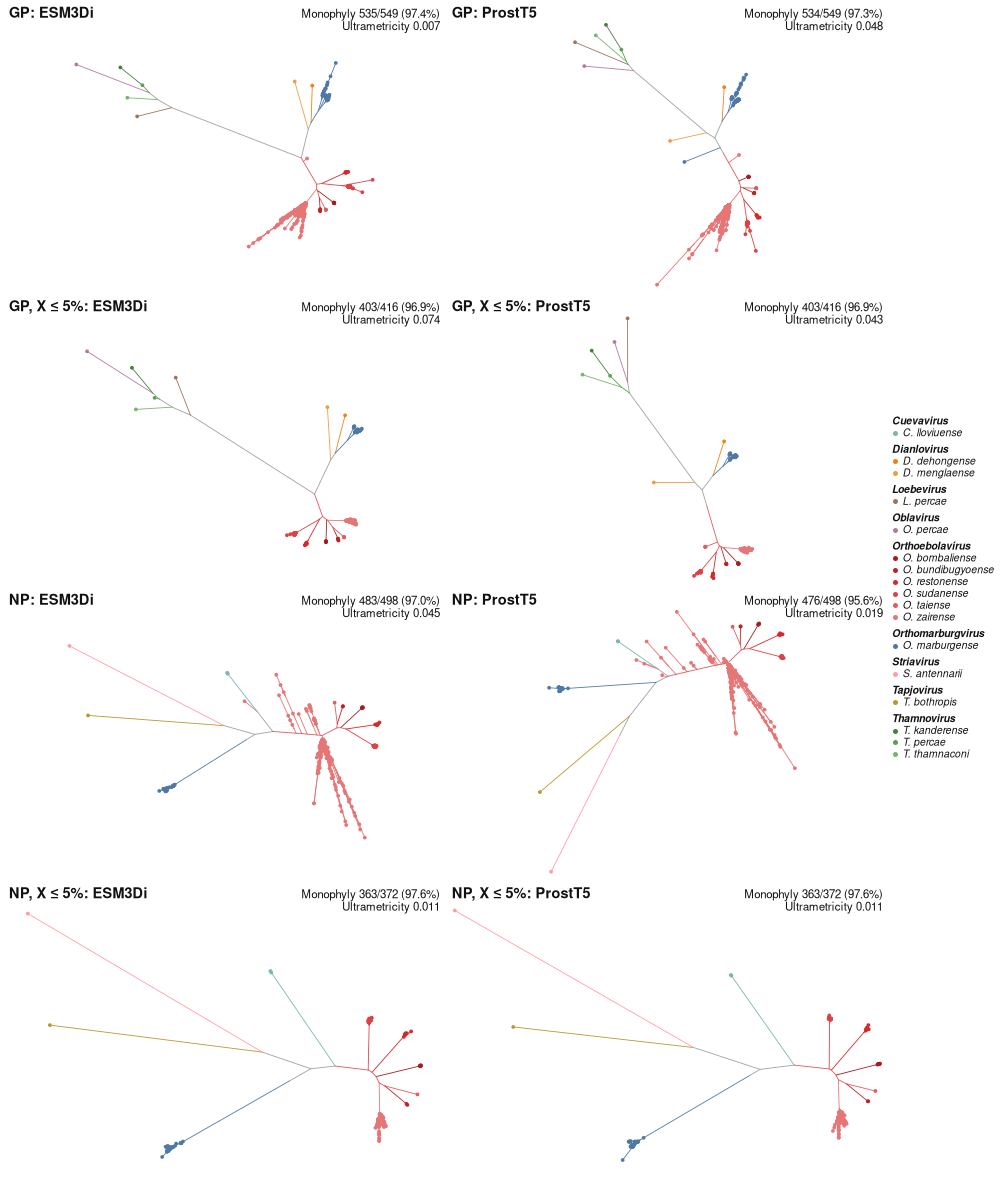

filoviridae_gp_full_trees: score table covering 0.0 mm2 of tree, with its margin


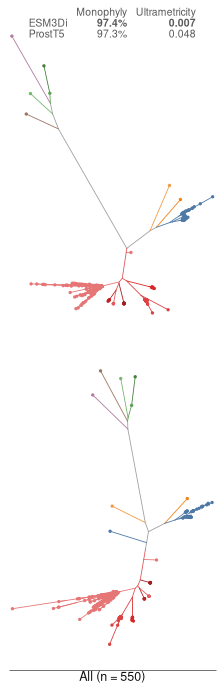

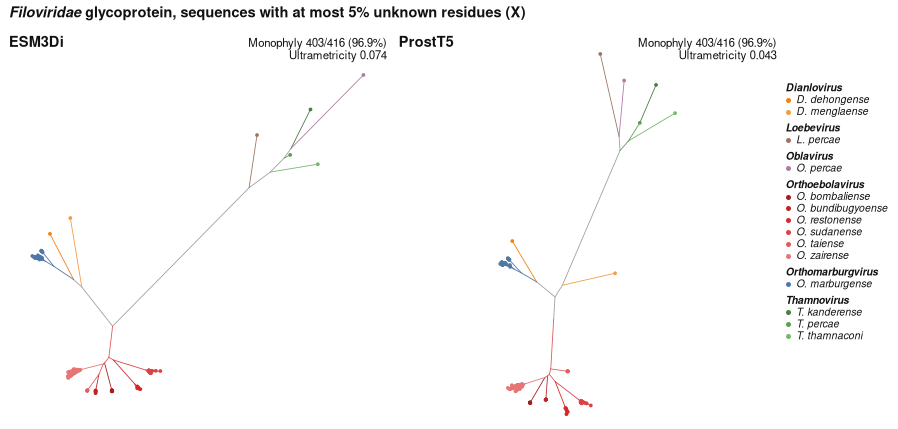

In [15]:
GENUS_COLORS = {   # Tableau 10, hues of similar strength
    "Orthoebolavirus": "#E15759",     # red
    "Orthomarburgvirus": "#4E79A7",   # blue
    "Dianlovirus": "#F28E2B",         # orange
    "Cuevavirus": "#76B7B2",          # teal
    "Thamnovirus": "#59A14F",         # green
    "Oblavirus": "#B07AA1",           # purple
    "Loebevirus": "#9C755F",          # brown
    "Striavirus": "#FF9DA7",          # pink
    "Tapjovirus": "#B6992D",          # olive
}
METHOD_TITLES = {"esm3di": "ESM3Di", "prostt5": "ProstT5"}
MODE = "scientific"


def monophyly_note(tree_file):
    """Monophyletic internal nodes of a tree, as ``535/549 (97.4%)``."""
    monophyletic, internal, fraction = score_monophyly(tree_file, verbose=False)
    return f"Monophyly {monophyletic}/{internal} ({fraction:.1%})"


def tree_entry(file, title, part=None):
    """Title on the first line, the scores at the top right of the tree (monophyly, ultrametricity), as in every tree of the paper."""
    return dict(file=file, title=title, part=part, corner=[monophyly_note(file), f"Ultrametricity {ultrametricity(file):.3f}"])


all_trees = [labelled_tree(m, p) for p in PROTEINS for m in MODELS] + [filtered_tree(m, p) for p in PROTEINS for m in MODELS]
colors = species_colors(tip_keys(all_trees, MODE), GENUS_COLORS)
style = dict(mode=MODE, colors=colors, genus_colors=GENUS_COLORS)

# Supplementary figure: one row per data set, each at its own scale
rows = {"GP": {m: labelled_tree(m, "gp") for m in MODELS}, "GP, X ≤ 5%": {m: filtered_tree(m, "gp") for m in MODELS},
        "NP": {m: labelled_tree(m, "np") for m in MODELS}, "NP, X ≤ 5%": {m: filtered_tree(m, "np") for m in MODELS}}
tree_grid([[tree_entry(tree, f"{name}: {METHOD_TITLES[m]}") for m, tree in trees.items()] for name, trees in rows.items()],
          FIGURE_DIR / "filoviridae_trees",
          legend_blocks=species_legend(colors, tip_keys([t for trees in rows.values() for t in trees.values()], MODE)),
          tree_width_mm=75, tree_height_mm=45, scale_by="row", **style)

# Figure 2a, right: all GP sequences, beside the species trees of the same method, which carry the method's name and the
# legend. Narrow and tall, so that the trees stay large in a narrow panel; slightly smaller tips for the dense clades.
# The column is named once, above the first tree; one table holds the monophyly and ultrametricity of the trees
# of this column, as in panel b.
gp_tips = len(Phylo.read(labelled_tree(MODELS[0], "gp"), "newick").get_terminals())
gp_scores = score_table([("Monophyly", "higher", ".1%"), ("Ultrametricity", "lower", ".3f")],
                        [(METHOD_TITLES[m], score_monophyly(labelled_tree(m, "gp"), verbose=False)[2], ultrametricity(labelled_tree(m, "gp")))
                         for m in MODELS])
tree_grid([[dict(file=labelled_tree(m, "gp"), title="", header=f"All (n = {gp_tips})" if m == MODELS[0] else None)]
           for m in MODELS],
          FIGURE_DIR / "filoviridae_gp_full_trees", legend_blocks=None, legend_inside=True, score_table=gp_scores, score_table_top_mm=FIGURE2_SCORE_TABLE_TOP_MM, transparent=True,
          header_bottom=True,
          tree_width_mm=37, height_mm=FIGURE2_PANEL_HEIGHT_MM, tip_diameter=1.6, fill_together=True, **style)

# Supplementary figure: the GP trees without X-rich sequences
tree_grid([[tree_entry(filtered_tree(m, "gp"), METHOD_TITLES[m]) for m in MODELS]],
          FIGURE_DIR / "filoviridae_gp_filtered_trees",
          legend_blocks=species_legend(colors, tip_keys([filtered_tree(m, "gp") for m in MODELS], MODE)),
          tree_width_mm=66, tree_height_mm=62,
          heading=[("Filoviridae", dict(fontweight="bold", fontstyle="italic")),
                   (" glycoprotein, sequences with at most 5% unknown residues (X)", dict(fontweight="bold"))], **style)


filoviridae_gp_species_trees: legend covering 0.0 mm2 of tree


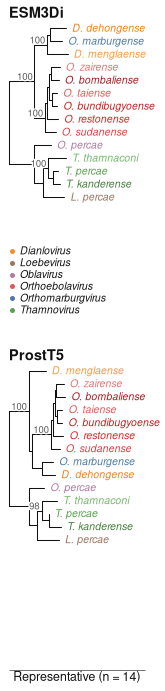

filoviridae_species_trees: legend covering 0.0 mm2 of tree


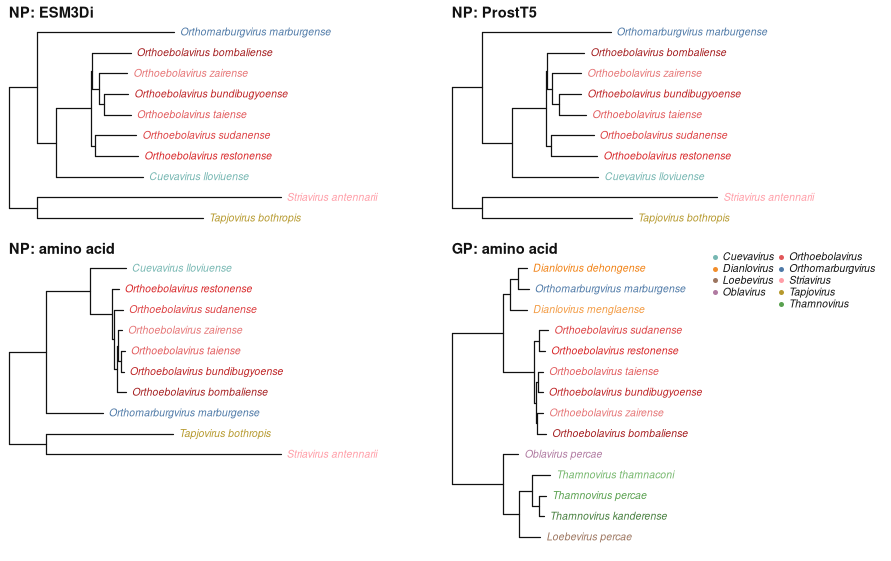

In [16]:
MAMMALIAN = {"Orthoebolavirus", "Cuevavirus", "Orthomarburgvirus", "Dianlovirus"}


def rooted_species_tree(tree_file):
    """Root between the mammalian filoviruses and the rest."""
    tree = toytree.tree(str(tree_file))
    tips = tree.get_tip_labels()
    tree = tree.root(next(tip for tip in tips if genus(tip) in MAMMALIAN))   # root inside the mammals first
    return tree.root(*[tip for tip in tips if genus(tip) not in MAMMALIAN])


def clade_support(tree, protein_name, method):
    """Per tested clade, the share of the DRAWS random choices of representatives whose tree recovers it,
    as a percentage, keyed by the clade's tips in this tree. A clade the tree itself does not recover has
    no node to carry the number, so it simply gets none."""
    tips = tree.get_tip_labels()
    support = {}
    for test, genera in GENUS_TESTS.items():
        share = draw_shares.loc[(protein_name, method), test] if test in draw_shares else np.nan
        group = frozenset(tip for tip in tips if genus(tip) in genera)
        if not pd.isna(share) and 2 <= len(group) <= len(tips) - 2:
            support[group] = f"{share * 100:.0f}"
    return support


def species_entry(tree_file, title, scale="3Di", note=None, subtitle=None, header=None, header_rule_mm=23, support=None):
    tree = rooted_species_tree(tree_file)
    return dict(tree=tree, title=title, scale=scale, note=note, subtitle=subtitle, header=header,
                header_rule_mm=header_rule_mm, support=clade_support(tree, *support) if support else None)


def species_figure(rows, output, legend=True, **size):
    """A grid of trees, with a legend of the genera they hold if ``legend``."""
    tips = [tip for row in rows for entry in row for tip in entry["tree"].get_tip_labels()]
    genera = {genus(tip) for tip in tips}
    # the legend carries every shade of a genus that this figure shows, so that all the shades of one hue
    # read as one genus (the species themselves are named on the tips)
    keys = {parse_tip(tip, MODE) for tip in tips}
    blocks = genus_legend(GENUS_COLORS, genera, colors=colors, keys=keys) if legend else None
    species_tree_grid(rows, output, colors=colors, legend_blocks=blocks, **size)


AMINO_ACID = "Amino acid (IQ-TREE)"
# Figure 2a, left: ESM3Di above ProstT5, small, with the genera abbreviated and the legend of the panel;
# the column is named once, above the first tree
gp_species = toytree.tree(str(genus_trees["gp"][METHOD_NAMES[MODELS[0]]])).ntips
species_figure([[species_entry(genus_trees["gp"][METHOD_NAMES[m]], METHOD_TITLES[m],
                               header=f"Representative (n = {gp_species})" if m == MODELS[0] else None,
                               support=("GP", METHOD_NAMES[m]))] for m in MODELS],
               FIGURE_DIR / "filoviridae_gp_species_trees", width_mm=27, row_mm=FIGURE2_PANEL_HEIGHT_MM / 2, tip_mm=2.2,
               abbreviate=True, linewidth=0.5, legend_columns=1, legend_left_mm=1, legend_top_mm=41, header_bottom=True)
# Supplementary figure: the other species trees. 3Di and amino-acid distances have different units, so each has its own scale
species_figure([[species_entry(genus_trees["np"][METHOD_NAMES[m]], f"NP: {METHOD_TITLES[m]}") for m in MODELS],
                [species_entry(genus_trees[p][AMINO_ACID], f"{PROTEINS[p]}: amino acid", scale="amino acid") for p in ("np", "gp")]],
               FIGURE_DIR / "filoviridae_species_trees", width_mm=75, row_mm=(40, 54), tip_mm=3.5)
